# Customer Churn Prediction (Telco) – End-to-End ML Project

**Goal:** Predict which telecom customers are likely to leave (churn) so the business can target them with retention offers.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns)
- Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn


**Workflow:**
1. Setup & data loading
2. Data cleaning
3. Exploratory data analysis (EDA)
4. Feature engineering
5. Train/test split & preprocessing pipeline
6. Baseline models + cross-validation
7. Hyperparameter tuning
8. Evaluation (ROC, PR curve, confusion matrix)
9. Threshold tuning (business-driven)
10. Explainability (feature importance, SHAP)
11. Business insights & save model

## Step 1 – Setup & Load Data

In [2]:
import os, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
os.makedirs("data", exist_ok=True)
PATH = "data/Telco-Customer-Churn.csv"
if not os.path.exists(PATH):
    urllib.request.urlretrieve(URL, PATH)

df = pd.read_csv(PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2 – Data Understanding & Cleaning

**Known issue in this dataset:** `TotalCharges` is stored as text because 11 rows contain a blank space. Those are brand-new customers (tenure = 0), so their total charge is logically 0.

In [3]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df['customerID'].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
# Convert TotalCharges to numeric; blanks become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])

# These rows have tenure == 0 (new customers) -> total charges = 0
print(df[df['TotalCharges'].isna()][['tenure', 'MonthlyCharges', 'TotalCharges']].head())
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# customerID is only an identifier -> no predictive value, drop it
df = df.drop(columns=['customerID'])

# Target: Yes/No -> 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['Churn'].value_counts()

Missing values:
 TotalCharges    11
dtype: int64
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN


Churn
0    5174
1    1869
Name: count, dtype: int64

## Step 3 – Exploratory Data Analysis (EDA)of the project.

### 3.1 Class balance
Churn is imbalanced (~26.5% churners). So **accuracy alone is misleading** (predicting "no churn" for everyone gives ~73.5% accuracy). We'll focus on Recall, Precision, F1 and ROC-AUC.

Churn rate: 26.54%


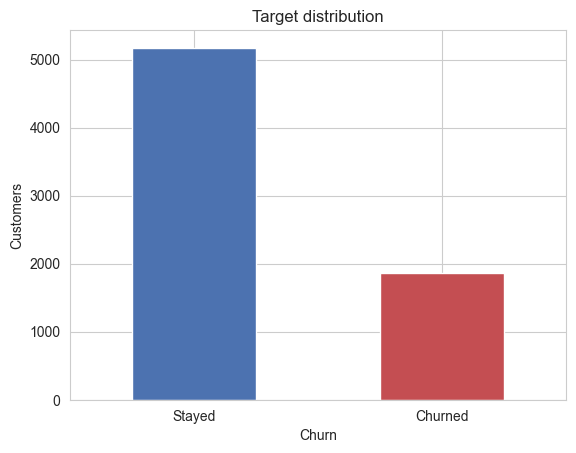

In [5]:
rate = df['Churn'].mean()
print(f"Churn rate: {rate:.2%}")
ax = df['Churn'].value_counts().rename({0:'Stayed', 1:'Churned'}).plot(kind='bar', color=['#4C72B0', '#C44E52'])
ax.set_title("Target distribution"); ax.set_ylabel("Customers"); plt.xticks(rotation=0)
plt.show()

### 3.2 Numeric features vs churn
Churners tend to have low tenure and higher monthly charges.

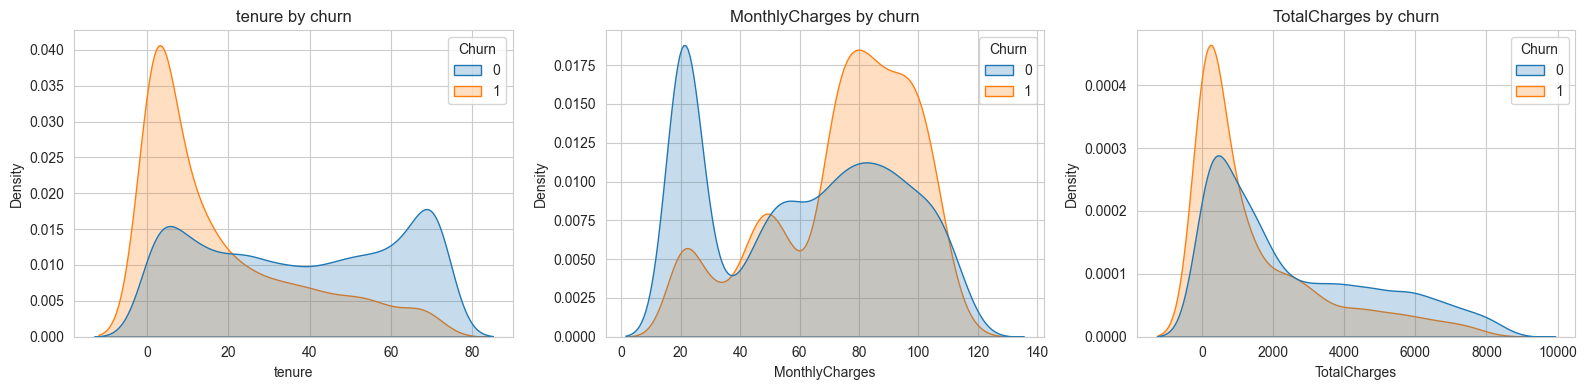

In [6]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.kdeplot(data=df, x=c, hue='Churn', fill=True, common_norm=False, ax=ax)
    ax.set_title(f"{c} by churn")
plt.tight_layout(); plt.show()

### 3.3 Categorical features vs churn rate
We plot the **churn rate** per category (not raw counts) so categories of different sizes can be compared fairly.

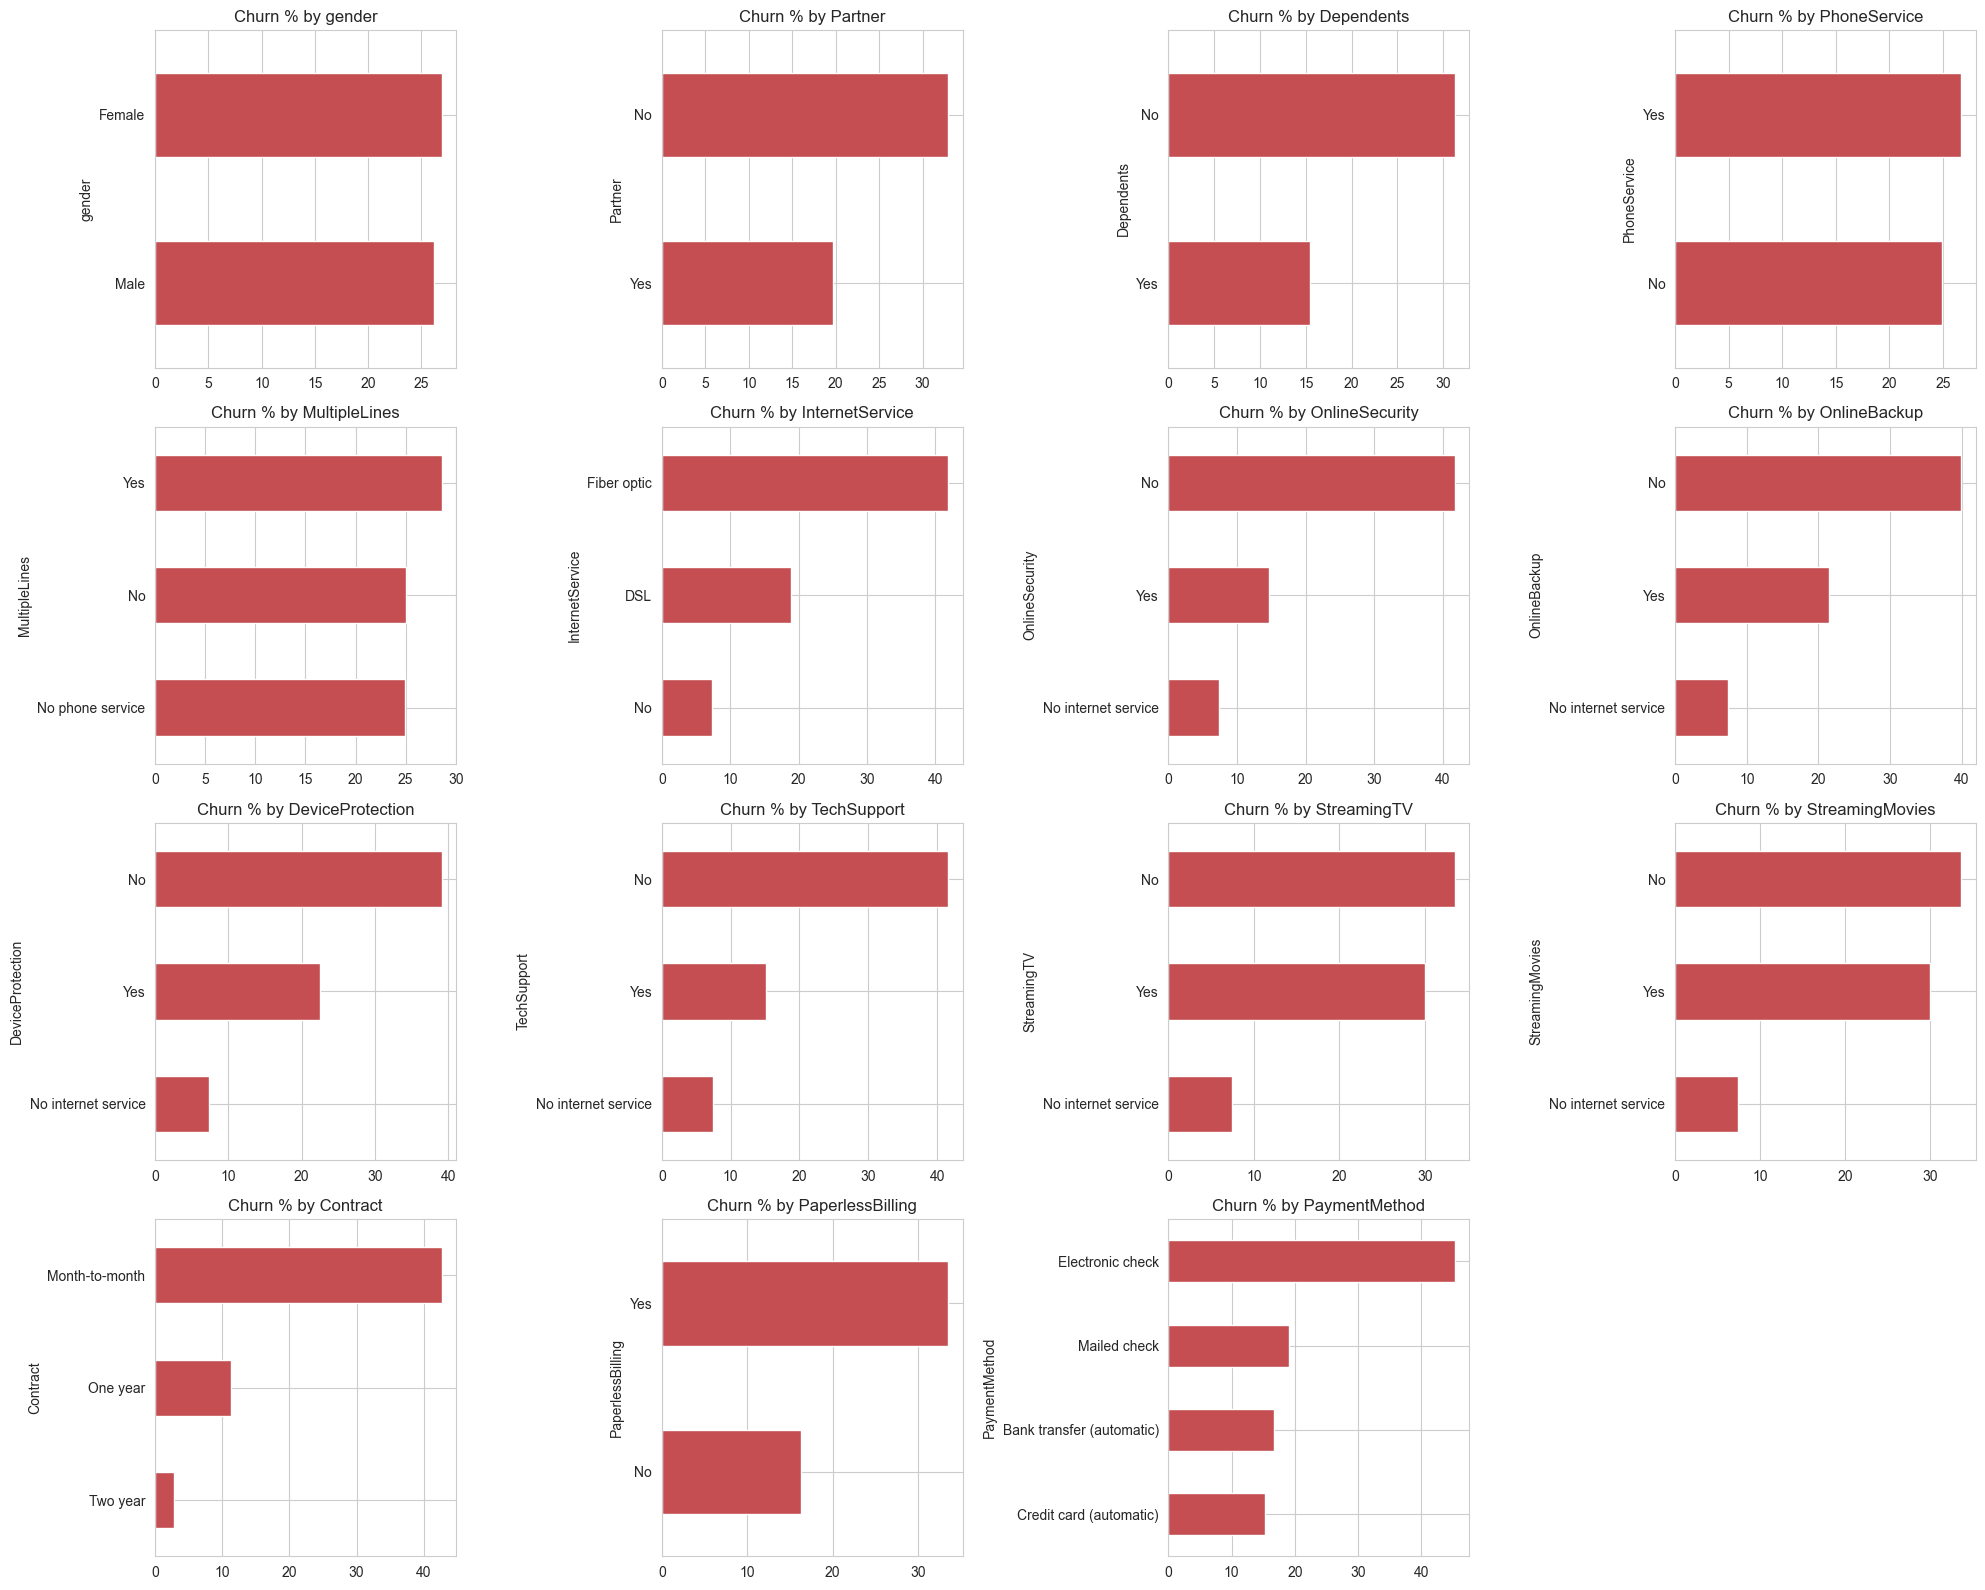

In [7]:
cat_cols = [c for c in df.select_dtypes('object').columns]
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()
for i, c in enumerate(cat_cols):
    (df.groupby(c)['Churn'].mean() * 100).sort_values().plot(kind='barh', ax=axes[i], color='#C44E52')
    axes[i].set_title(f"Churn % by {c}"); axes[i].set_xlabel("")
for j in range(len(cat_cols), len(axes)):
    axes[j].axis('off')
plt.tight_layout(); plt.show()

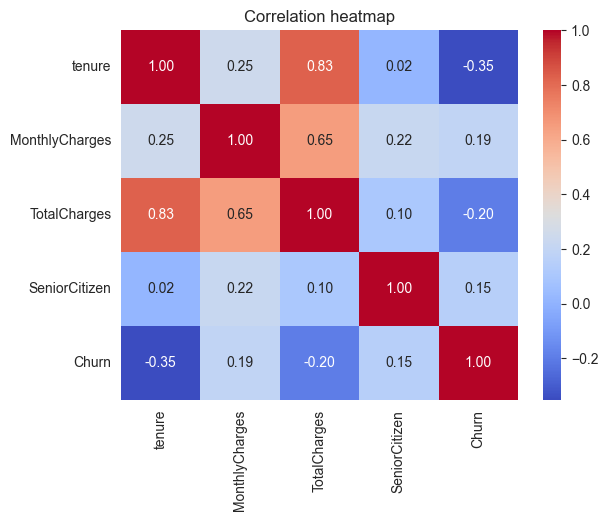

In [8]:
# Correlation among numeric features
sns.heatmap(df[num_cols + ['SeniorCitizen', 'Churn']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation heatmap"); plt.show()

## Step 4 – Feature Engineering
**What we do:** create new features that capture business logic.

- `tenure_group`: bucket tenure into customer-lifecycle stages
- `num_services`: how many add-on services the customer uses (more services → more "sticky")
- `avg_monthly_spend`: TotalCharges / tenure
- `charge_gap`: current MonthlyCharges minus historical average (a price-hike signal)

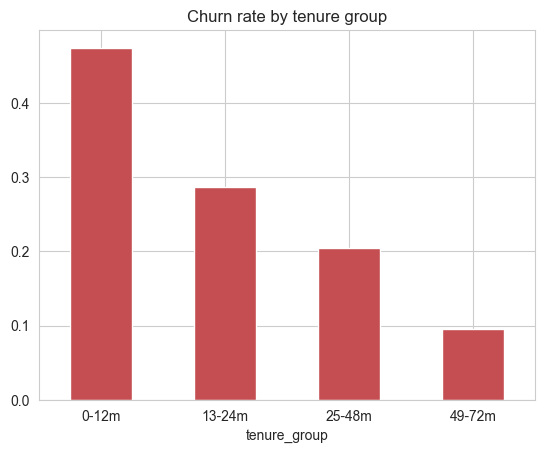

In [9]:
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']

df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 72],
                            labels=['0-12m', '13-24m', '25-48m', '49-72m']).astype(str)
df['num_services'] = (df[service_cols] == 'Yes').sum(axis=1) + (df['InternetService'] != 'No').astype(int)
df['avg_monthly_spend'] = np.where(df['tenure'] > 0, df['TotalCharges'] / df['tenure'], df['MonthlyCharges'])
df['charge_gap'] = df['MonthlyCharges'] - df['avg_monthly_spend']

df.groupby('tenure_group')['Churn'].mean().plot(kind='bar', color='#C44E52', title="Churn rate by tenure group")
plt.xticks(rotation=0); plt.show()

## Step 5 – Train/Test Split & Preprocessing Pipeline
**What I did:**
1. Split data 80/20 using `stratify` so both sets keep the same churn ratio.
2. Build a `ColumnTransformer`: scale numeric columns, one-hot encode categorical ones.
3. Wrap it in a `Pipeline` with the model. **This prevents data leakage** (scaler/encoder learn only from training folds), a very common interview question.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

X = df.drop(columns='Churn')
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric:", num_features)
print("Categorical:", cat_features)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
])
print(X_train.shape, X_test.shape)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'avg_monthly_spend', 'charge_gap']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']
(5634, 23) (1409, 23)


## Step 6 – Baseline Models with Cross-Validation
**What we do:** compare 3 models using 5-fold stratified CV and the metrics that matter for imbalanced data.

- **Logistic Regression** – simple, interpretable baseline
- **Random Forest** – bagged trees, handles non-linearity
- **XGBoost** – gradient boosting, usually the strongest on tabular data

**Imbalance handling:** `class_weight='balanced'` and `scale_pos_weight` make the model penalise missing a churner more heavily.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=neg/pos,
                             eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['roc_auc', 'average_precision', 'recall', 'precision', 'f1']

rows = []
for name, m in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, **{k.replace('test_', ''): v.mean() for k, v in s.items() if k.startswith('test_')}})

cv_results = pd.DataFrame(rows).set_index("Model").round(3)
cv_results

,roc_auc,average_precision,recall,precision,f1
Model,,,,,
Logistic Regression,0.846,0.662,0.798,0.519,0.629
Random Forest,0.829,0.624,0.464,0.652,0.542
XGBoost,0.842,0.656,0.759,0.534,0.627


**How to read it:** `roc_auc` = overall ranking quality; `average_precision` = area under the precision-recall curve (better for imbalance); `recall` = % of real churners we catch; `precision` = % of flagged customers who really churn.

## Step 7 – Hyperparameter Tuning
**What we do:** tune the best-performing model (Logistic Regression or XGBoost usually win here) with `RandomizedSearchCV`, optimising ROC-AUC. Random search is much faster than grid search and nearly as good.

In [13]:
from sklearn.model_selection import RandomizedSearchCV

xgb_pipe = Pipeline([('prep', preprocessor),
                     ('model', XGBClassifier(scale_pos_weight=neg/pos, eval_metric='logloss',
                                             random_state=RANDOM_STATE, n_jobs=-1))])

param_dist = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [2, 3, 4, 5],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__subsample': [0.7, 0.8, 1.0],
    'model__colsample_bytree': [0.7, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5],
    'model__reg_lambda': [1, 5, 10],
}

search = RandomizedSearchCV(xgb_pipe, param_dist, n_iter=30, scoring='roc_auc', cv=cv,
                            random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
print("Best params:", search.best_params_)
best_model = search.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV ROC-AUC: 0.8492
Best params: {'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 2, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.7}


## Step 8 – Final Evaluation on the Held-out Test Set


              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.51      0.81      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.81      0.74      0.76      1409

ROC-AUC: 0.8455
PR-AUC : 0.6653


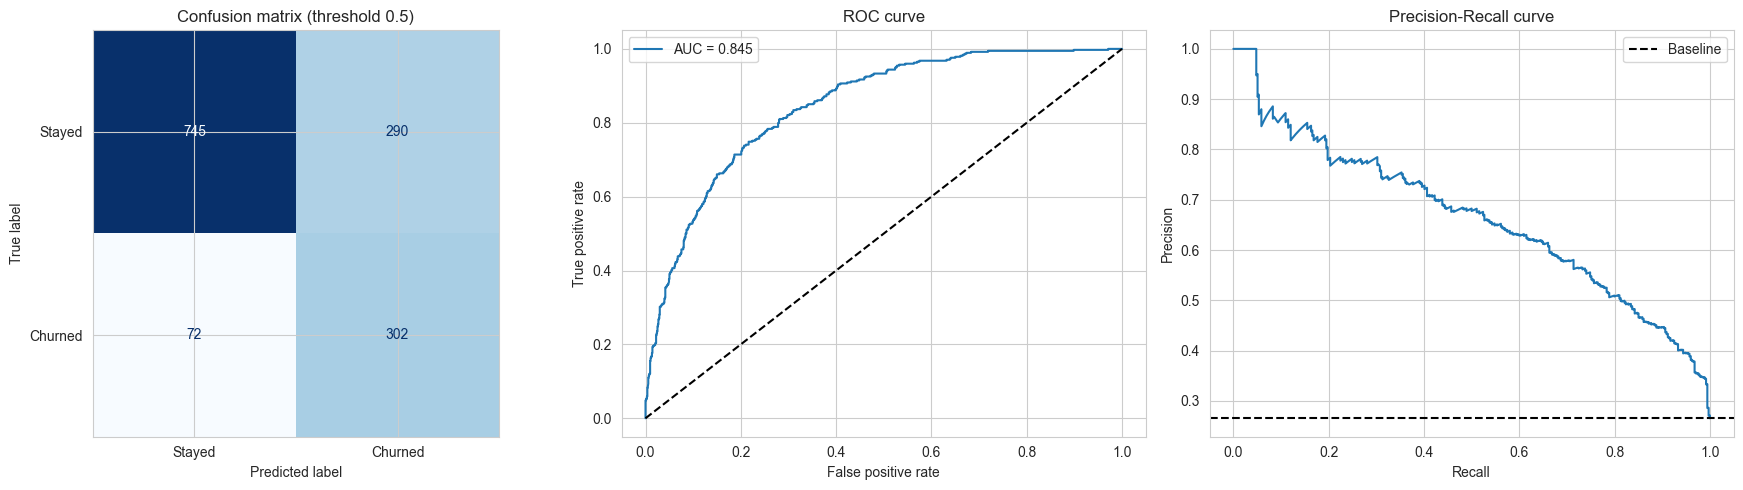

In [14]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score)

proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(classification_report(y_test, pred, target_names=['Stayed', 'Churned']))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("PR-AUC :", round(average_precision_score(y_test, proba), 4))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Stayed', 'Churned']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title("Confusion matrix (threshold 0.5)")

fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}"); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_title("ROC curve"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend()

p, r, _ = precision_recall_curve(y_test, proba)
ax[2].plot(r, p); ax[2].axhline(y_test.mean(), color='k', ls='--', label='Baseline')
ax[2].set_title("Precision-Recall curve"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].legend()
plt.tight_layout(); plt.show()

## Step 9 – Business-Driven Threshold Tuning
**What we do:** the default 0.5 cut-off isn't sacred. In churn, missing a churner (false negative) usually costs more than sending a discount to a loyal customer (false positive).

We assume (change these to your own numbers):
- Retention offer cost per flagged customer: **$20**
- Value of saving a churner: **$200** (assume the offer succeeds 40% of the time)

Then we pick the threshold that maximises expected profit. This turns a ML project into a **business project**, which is great on a CV.

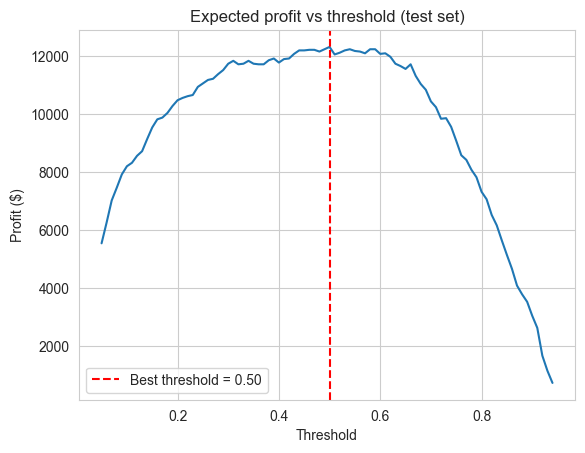

              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.51      0.81      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.81      0.74      0.76      1409

Profit at 0.5: $12,320 | Profit at 0.50: $12,320


In [15]:
OFFER_COST, SAVE_VALUE, SUCCESS_RATE = 20, 200, 0.40

thresholds = np.arange(0.05, 0.95, 0.01)
profits = []
for t in thresholds:
    flagged = proba >= t
    tp = ((flagged) & (y_test == 1)).sum()
    profit = tp * SUCCESS_RATE * SAVE_VALUE - flagged.sum() * OFFER_COST
    profits.append(profit)

best_t = thresholds[int(np.argmax(profits))]
plt.plot(thresholds, profits); plt.axvline(best_t, color='r', ls='--', label=f"Best threshold = {best_t:.2f}")
plt.title("Expected profit vs threshold (test set)"); plt.xlabel("Threshold"); plt.ylabel("Profit ($)"); plt.legend(); plt.show()

pred_opt = (proba >= best_t).astype(int)
print(classification_report(y_test, pred_opt, target_names=['Stayed', 'Churned']))
print(f"Profit at 0.5: ${profits[int(np.argmin(abs(thresholds-0.5)))]:,.0f} | Profit at {best_t:.2f}: ${max(profits):,.0f}")

## Step 10 – Explainability
**What we do:** a model nobody understands won't be trusted by business teams. We use:
1. **Permutation importance** – how much does performance drop when a feature is shuffled?
2. **SHAP** – shows the direction and size of each feature's effect.

In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, scoring='roc_auc', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
imp.tail(12).plot(kind='barh', figsize=(8, 5), color='#4C72B0', title="Permutation importance (drop in ROC-AUC)")
plt.show()

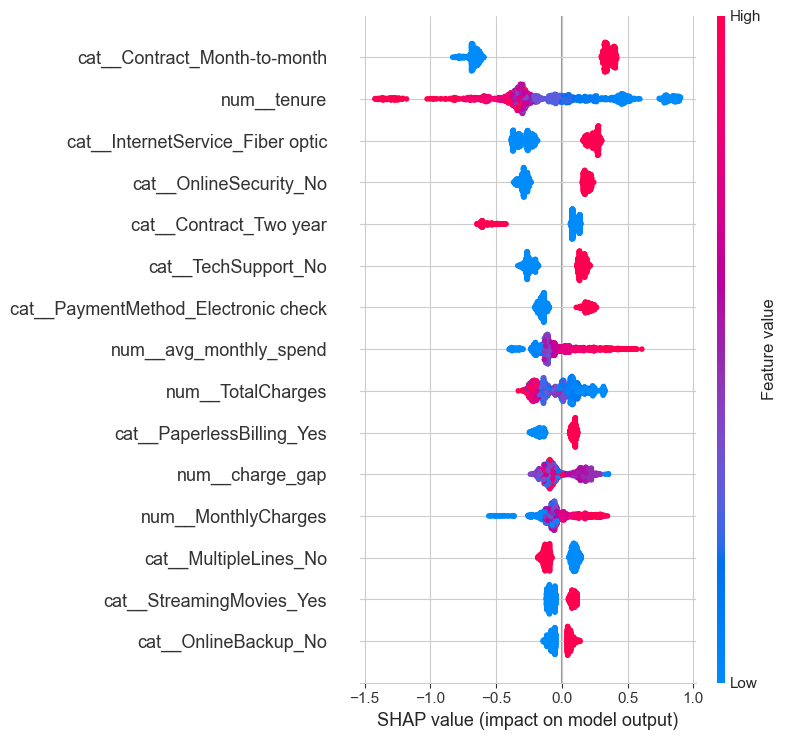

In [17]:
import shap

prep = best_model.named_steps['prep']
xgb = best_model.named_steps['model']
X_test_t = prep.transform(X_test)
feature_names = prep.get_feature_names_out()
X_test_df = pd.DataFrame(X_test_t.toarray() if hasattr(X_test_t, 'toarray') else X_test_t, columns=feature_names)

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_df)
shap.summary_plot(shap_values, X_test_df, max_display=15)

**Reading SHAP:** each dot is a customer. Red = high feature value, blue = low. Dots to the right push the prediction toward **churn**. Example: low `tenure` (blue) on the right means new customers are riskier.

## Step 11 – Business Insights, Risk Segmentation & Saving the Model
**What we do:** score every customer, bucket into risk tiers for a retention team, then save the model so it can be reused (and later deployed with Streamlit/Flask).

In [18]:
scored = X_test.copy()
scored['churn_probability'] = proba
scored['actual'] = y_test.values
scored['risk_tier'] = pd.cut(scored['churn_probability'], bins=[0, 0.3, 0.6, 1.0], labels=['Low', 'Medium', 'High'])

summary = scored.groupby('risk_tier').agg(customers=('actual', 'size'), actual_churn_rate=('actual', 'mean')).round(3)
print(summary)
scored.sort_values('churn_probability', ascending=False)[['Contract', 'tenure', 'MonthlyCharges', 'churn_probability']].head(10)

           customers  actual_churn_rate
risk_tier                              
Low              640              0.055
Medium           289              0.235
High             480              0.565


,Contract,tenure,MonthlyCharges,churn_probability
3380,Month-to-month,1,95.10,0.969818
6866,Month-to-month,1,95.45,0.965727
4585,Month-to-month,1,85.05,0.957553
2797,Month-to-month,3,100.95,0.948676
6748,Month-to-month,1,85.00,0.948175
6623,Month-to-month,1,76.45,0.947455
642,Month-to-month,1,89.55,0.946585
2397,Month-to-month,1,88.35,0.944239
2464,Month-to-month,1,77.15,0.942390
5943,Month-to-month,1,84.85,0.941943


In [19]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump({"model": best_model, "threshold": float(best_t)}, "models/churn_model.pkl")

# Reload test
loaded = joblib.load("models/churn_model.pkl")
sample = X_test.iloc[[0]]
p = loaded["model"].predict_proba(sample)[0, 1]
print(f"Churn probability: {p:.2%} -> {'CHURN RISK' if p >= loaded['threshold'] else 'Likely to stay'}")

Churn probability: 13.29% -> Likely to stay
